# Terceira --> Ilha 23

In [41]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_23 = pd.read_csv('df_23_d.csv')
df_23_y = pd.read_csv('df_23_y_d.csv')

df_23['ID'] = [i for i in range(len(df_23))]
df_23_y['ID'] = [i for i in range(len(df_23_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [42]:
df_23

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,32,2021,0.285714,True,0.14,0.12,True,0.142857,0.690890,-0.252747,0
1,52,1986,0.428571,True,0.50,0.34,True,1.000000,0.688664,-0.253383,1
2,57,True,0.285714,True,0.22,0.22,True,0.142857,0.690940,-0.252777,2
3,59,2006,0.285714,True,0.10,0.08,True,0.285714,0.689053,-0.253762,3
4,69,True,0.214286,True,0.14,0.14,True,0.285714,0.688775,-0.253226,4
...,...,...,...,...,...,...,...,...,...,...,...
426,4439,True,0.285714,Garden,0.38,0.38,d,0.142857,0.691046,-0.254383,426
427,4457,True,0.500000,Air conditioning,0.32,0.32,True,0.142857,0.689140,-0.251912,427
428,4460,True,0.428571,True,0.18,0.18,True,0.428571,0.688817,-0.253458,428
429,4468,1994,1.000000,True,0.34,0.30,d,0.142857,0.688862,-0.253605,429


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

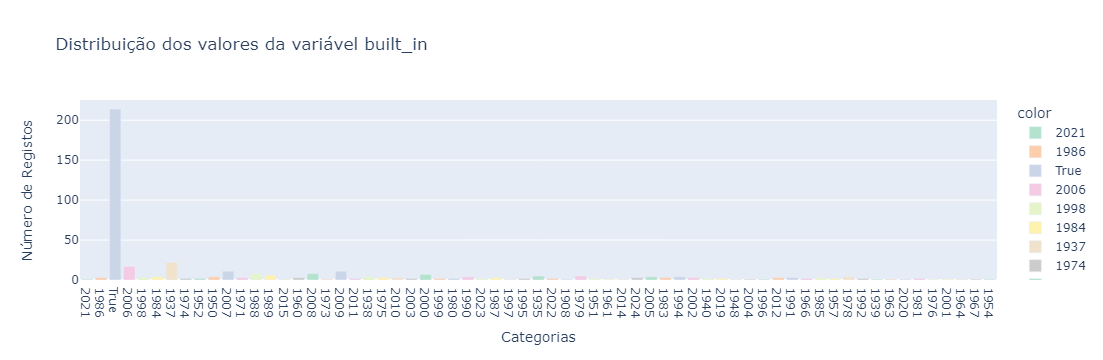

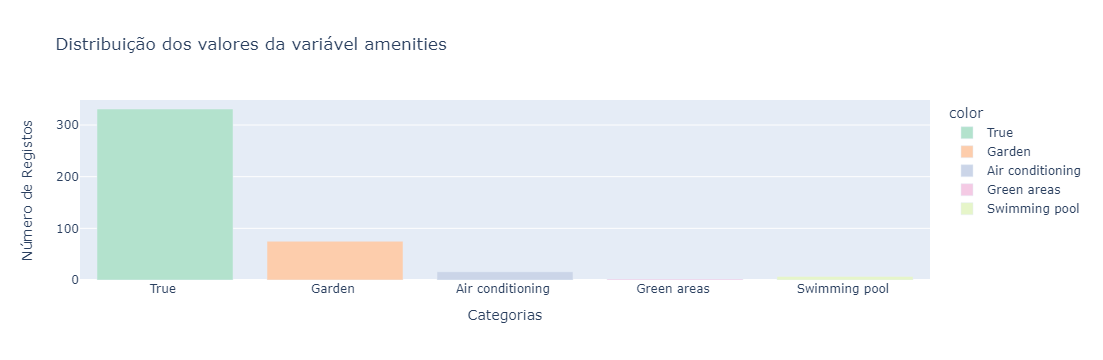

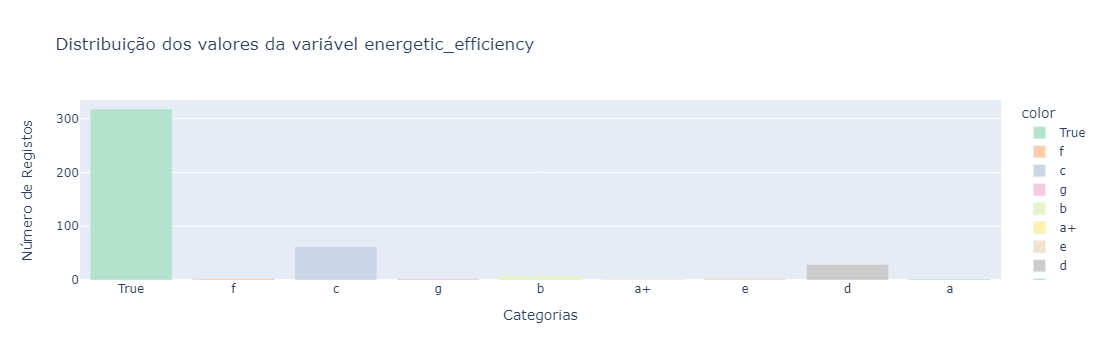

In [43]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_23[nome].unique()
    for i in df_23[nome].unique():
        bt2 = df_23[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_23, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [44]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true23 = list(df_23.loc[df_23['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_a_mais23 = list(df_23.loc[df_23['energetic_efficiency'] == 'a+', 'ID']) # como só havia 1 sample replicar 2x
ids_a23 = list(df_23.loc[df_23['energetic_efficiency'] == 'a', 'ID']) # como só havia 1 sample replicar 2x
ids_outros23 = list(df_23.loc[df_23['energetic_efficiency'] != 'True', 'ID'])

# Como há elementos só com 1 elemento meter mais 2 --> replicar
ids_outros23.append(ids_a_mais23[0])
ids_outros23.append(ids_a_mais23[0])
ids_outros23.append(ids_a23[0])
ids_outros23.append(ids_a23[0])

# Dados 
teste23 = df_23.loc[ids_true23,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y23 = df_23.loc[ids_true23,['energetic_efficiency']]
treino23 = df_23.loc[ids_outros23,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y23 = df_23.loc[ids_outros23,['energetic_efficiency']]

# Comparação --> X_train_23[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee23 = KNN(3, teste23, treino23, treino_y23)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_23 = sub_ee(ids_true23, l_ee23, df_23, 'energetic_efficiency')


ee23 = df_23.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee23 = substituir_energetic_efficiency(ee23)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee23 = norm_ee(ee23)

df_23['energetic_efficiency'] = ee23

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [45]:
aa23 = df_23.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa23 = substituir_amenities(aa23)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa23 = norm_amenities(aa23)

df_23['amenities'] = aa23

### --> built_in

In [46]:
id_true23 = list(df_23.loc[df_23['built_in'] == 'True', 'ID'])
id_outros23 = list(df_23.loc[df_23['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data23 = menos_2(df_23, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros23 = replicação_menos2(df_23, lista_data23, id_outros23)

# Dados 
# criar dataset com price

d_b23 =  df_23.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_223 = df_23_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b23 = d_b23.join(d_b_223)


teste_b23 = d_b23.loc[id_true23,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y23 = df_23.loc[ids_true23,['built_in']]
treino_b23 = d_b23.loc[id_outros23,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y23 = df_23.loc[id_outros23,['built_in']]

# KNN
l_b_i23 = KNN(3, teste_b23, treino_b23, treino_b_y23)

# Substituir
df_23 = sub_ee(id_true23, l_b_i23, df_23, 'built_in')

b_i23 = df_23.loc[:, ['built_in']]
b_i23['built_in'] = b_i23['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i23 = norm_b_i(b_i23)

df_23['built_in'] = b_i23

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [47]:
df_23

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,32,0.998518,0.285714,0.090909,0.14,0.12,0.555556,0.142857,0.690890,-0.252747,0
1,52,0.981225,0.428571,0.090909,0.50,0.34,0.555556,1.000000,0.688664,-0.253383,1
2,57,0.998024,0.285714,0.090909,0.22,0.22,0.555556,0.142857,0.690940,-0.252777,2
3,59,0.991107,0.285714,0.090909,0.10,0.08,0.555556,0.285714,0.689053,-0.253762,3
4,69,0.982213,0.214286,0.090909,0.14,0.14,0.555556,0.285714,0.688775,-0.253226,4
...,...,...,...,...,...,...,...,...,...,...,...
426,4439,0.989625,0.285714,0.272727,0.38,0.38,0.666667,0.142857,0.691046,-0.254383,426
427,4457,0.975296,0.500000,0.181818,0.32,0.32,0.666667,0.142857,0.689140,-0.251912,427
428,4460,0.957016,0.428571,0.090909,0.18,0.18,0.555556,0.428571,0.688817,-0.253458,428
429,4468,0.985178,1.000000,0.090909,0.34,0.30,0.666667,0.142857,0.688862,-0.253605,429


# Modelo

In [48]:

# Dividir em treino e teste

X_train_23, X_test_23, y_train_23, y_test_23 = train_test_split(df_23, df_23_y, test_size=0.25, random_state=42)
X_train_23

,Unnamed: 0,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
3,59,0.991107,0.285714,0.090909,0.10,0.08,0.555556,0.285714,0.689053,-0.253762,3
18,205,0.964427,0.214286,0.090909,0.16,0.14,0.666667,0.142857,0.688795,-0.253007,18
329,3516,0.991601,0.285714,0.090909,0.24,0.24,0.555556,0.142857,0.690580,-0.252309,329
60,590,0.985178,0.214286,0.090909,0.12,0.12,0.555556,0.428571,0.690071,-0.251925,60
255,2703,0.958004,0.285714,0.090909,0.38,0.38,0.555556,0.428571,0.691037,-0.254395,255
...,...,...,...,...,...,...,...,...,...,...,...
71,705,0.983202,0.214286,0.090909,0.08,0.08,0.555556,0.142857,0.689187,-0.254013,71
106,1114,0.957510,0.285714,0.090909,0.08,0.06,0.555556,0.142857,0.688817,-0.253458,106
270,2870,0.983202,0.142857,0.090909,0.06,0.06,0.555556,0.142857,0.691083,-0.254261,270
348,3690,0.977767,0.428571,0.272727,0.44,0.30,0.111111,0.142857,0.688706,-0.253437,348


In [49]:
X_train23 = X_train_23[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test23 = X_test_23[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train23 = y_train_23[['Price_norm']]
y_test23 = y_test_23[['Price_norm']]

# Gradient Boosting Regressor

In [50]:
"""
from sklearn import ensemble

gbd = ensemble.GradientBoostingRegressor(n_estimators = 100, max_depth = 8, min_samples_split = 2, learning_rate = 0.01, loss = 'squared_error')
gbd.fit(X_train23, y_train23)
y_pred_23 = gbd.predict(X_test23)
y_pred = [abs(x) for x in y_pred_23]
#print(y_pred_23)
print(mean_squared_error(y_pred_23,y_test23))
print(gbd.score(X_test23,y_test23))

### Guardar o modelo

import pickle

with open('modelo_dist23.pkl', 'wb') as file:
    pickle.dump(gbd, file)
"""

0.00011842505843574037
0.38870045497286


C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\ensemble\_gb.py:424: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [51]:
# abrir modelo

with open('modelo_dist23.pkl', 'rb') as f:
    GBD = pickle.load(f)
GBD

GradientBoostingRegressor(learning_rate=0.01, max_depth=8)

In [52]:
y_prev = GBD.predict(X_test23)

# OUTPUT E VIS

In [53]:
y_test23['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_5376\350632715.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [54]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test23['Price_prev'] = lista_des(y_prev)


def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test23 = df_criar_id(y_test23, df_23_y)

C:\Users\User\AppData\Local\Temp\ipykernel_5376\252455194.py:12: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_5376\252455194.py:18: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_5376\252455194.py:18: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_5376\2

In [55]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test23 =  intervalo_preco(y_test23)

In [56]:
y_test23

,Price_norm,prev_norm,Price_prev,Price_Real,Price_Prev_Int
423,0.018667,0.015018,225264.0,280000,"[218506.08, 232021.92]"
75,0.006000,0.010122,151832.0,90000,"[147277.04, 156386.96]"
296,0.003667,0.007552,113287.0,55000,"[109888.39, 116685.61]"
30,0.012467,0.015795,236920.0,187000,"[229812.4, 244027.6]"
362,0.014667,0.015018,225264.0,220000,"[218506.08, 232021.92]"
...,...,...,...,...,...
271,0.014667,0.014793,221889.0,220000,"[215232.33, 228545.67]"
16,0.016333,0.013707,205602.0,245000,"[199433.94, 211770.06]"
399,0.003050,0.015822,237332.0,45750,"[230212.04, 244451.96]"
131,0.026667,0.014316,214736.0,400000,"[208293.92, 221178.08]"


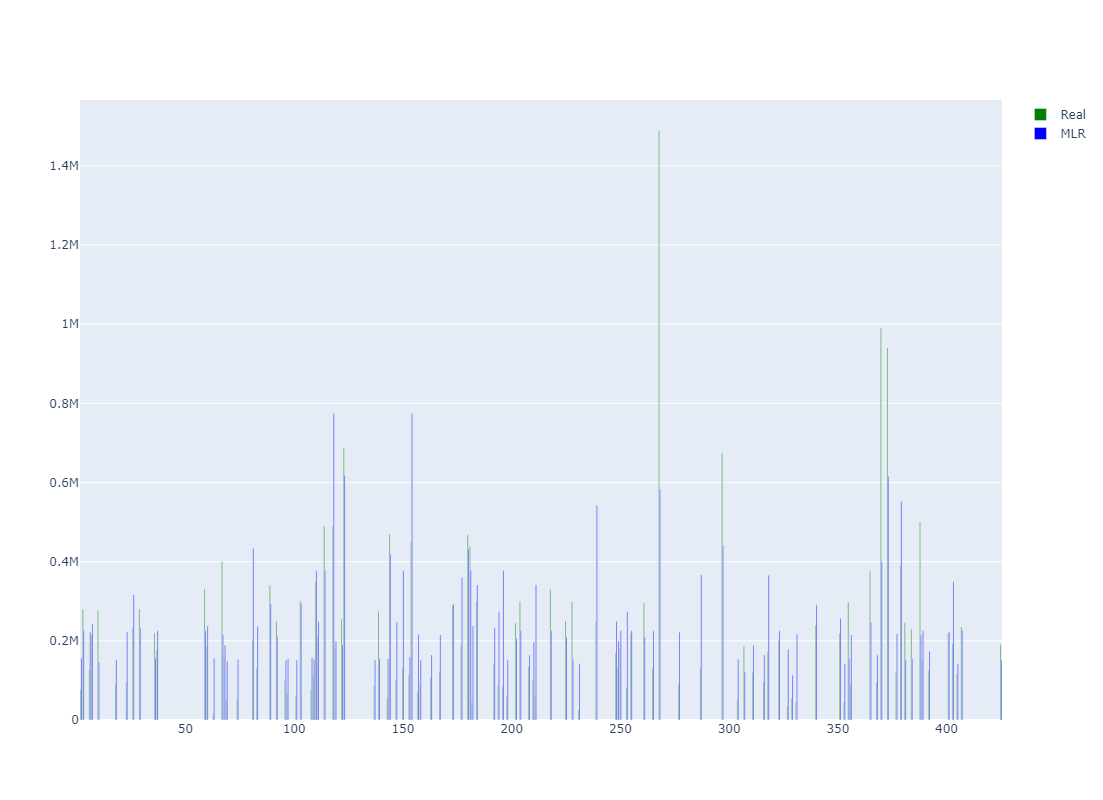

In [57]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_23.ID, y=y_test23.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_23.ID, y=y_test23.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()